# Wheat price forecasting from weather and WASDE data

In [2]:
from datetime import datetime, timezone

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests

IMF_WHEAT_URL = (
    "https://api.imf.org/external/sdmx/3.0/data/dataflow/IMF.RES/PCPS/9.0.0/"
    "*.PWHEAMT.USD.M?c%5BTIME_PERIOD%5D=ge:1956-12-31+le:2026-09-30"
    "&attributes=all&detail=full&includeHistory=true&limit=100"
)

retrieved_at = datetime.now(timezone.utc).isoformat()
response = requests.get(
    IMF_WHEAT_URL,
    headers={"Accept": "application/vnd.sdmx.data+json;version=2.0.0"},
    timeout=60,
)
response.raise_for_status()
imf_payload = response.json()
print(f"Retrieved at: {retrieved_at}")
print(f"HTTP status: {response.status_code}")

Retrieved at: 2026-11-10T08:33:54.893295+00:00
HTTP status: 200


In [3]:
def parse_imf_sdmx_series(payload):
    """Convert the returned SDMX-JSON wheat series to a tidy table."""
    data = payload["data"]
    structure = data["structures"][0]
    time_values = structure["dimensions"]["observation"][0]["values"]
    observations = data["dataSets"][0]["series"]
    if len(observations) != 1:
        raise ValueError(f"Expected one wheat series, found {len(observations)}")
    series = next(iter(observations.values()))["observations"]
    rows = []
    for index, observation in series.items():
        period_label = time_values[int(index)]["value"].replace("-M", "-")
        rows.append(
            {
                "date": pd.to_datetime(period_label, format="%Y-%m"),
                "wheat_price_usd": pd.to_numeric(observation[0], errors="coerce"),
            }
        )
    result = pd.DataFrame(rows).sort_values("date").reset_index(drop=True)
    if result["date"].duplicated().any():
        raise ValueError("IMF response produced duplicate monthly dates")
    if result["wheat_price_usd"].isna().all():
        raise ValueError("IMF wheat series contains no numeric observations")
    return result

wheat = parse_imf_sdmx_series(imf_payload)
wheat.head()

,date,wheat_price_usd
0,1992-01-01,169.954773
1,1992-02-01,177.130600
2,1992-03-01,169.350739
3,1992-04-01,159.931198
4,1992-05-01,149.689117


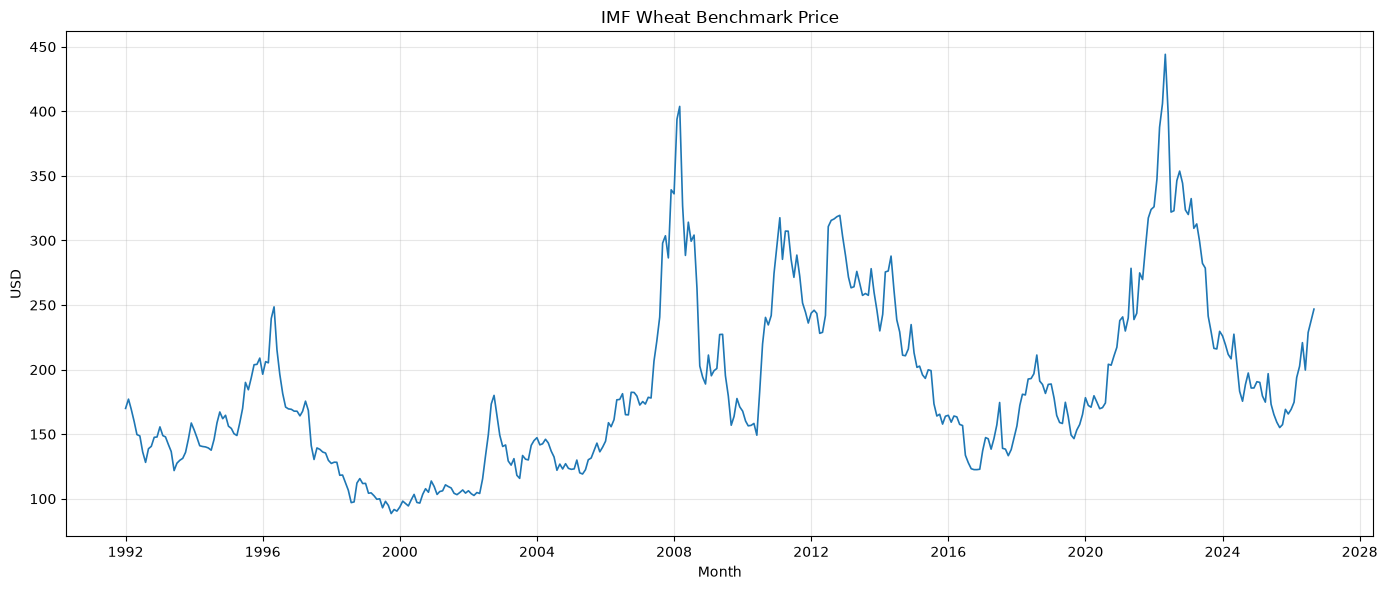

In [4]:
wheat["target_return_1m"] = (
    np.log(wheat["wheat_price_usd"].shift(-1))
    - np.log(wheat["wheat_price_usd"])
)

fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(wheat["date"], wheat["wheat_price_usd"], linewidth=1.2)
ax.set_title("IMF Wheat Benchmark Price")
ax.set_xlabel("Month")
ax.set_ylabel("USD")
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

## Weather and WASDE inputs

In [5]:
from io import StringIO
from lxml import html

roni_page_url = "https://www.cpc.ncep.noaa.gov/products/analysis_monitoring/enso/roni/"

roni_response = requests.get(roni_page_url, timeout=60)
roni_response.raise_for_status()

document = html.fromstring(roni_response.content)
matches = document.xpath(
    "/html/body/table[4]/tbody/tr/td[2]/table/tbody/tr[2]/td/div[1]/table[2]"
)

if len(matches) != 1:
    raise ValueError(f"Expected one target table, found {len(matches)}")

roni_table = pd.read_html(
    StringIO(html.tostring(matches[0], encoding="unicode"))
)[0]

roni_table

,Year The year,DJF Dec Jan Feb,JFM Jan Feb Mar,FMA Feb Mar Apr,MAM Mar Apr May,AMJ Apr May Jun,MJJ May Jun Jul,JJA Jun Jul Aug,JAS Jul Aug Sep,ASO Aug Sep Oct,SON Sep Oct Nov,OND Oct Nov Dec,NDJ Nov Dec Jan
0,1950,-1.2,-1.1,-1.0,-1.0,-1.0,-0.7,-0.4,-0.3,-0.3,-0.4,-0.4,-0.5
1,1951,-0.3,0.1,0.5,0.6,0.6,0.7,0.8,1.0,1.0,1.0,0.9,0.7
2,1952,0.7,0.3,0.5,0.2,0.0,-0.4,-0.4,-0.1,0.1,0.0,-0.1,0.1
3,1953,0.4,0.7,0.7,0.7,0.9,0.8,0.7,0.7,0.7,0.8,0.6,0.7
4,1954,0.6,0.6,0.3,0.0,-0.2,-0.2,-0.4,-0.6,-0.5,-0.3,-0.1,-0.2
...,...,...,...,...,...,...,...,...,...,...,...,...,...
79,2022,-1.2,-1.1,-1.2,-1.3,-1.2,-0.9,-0.9,-0.9,-1.1,-1.1,-1.1,-1.0
80,2023,-0.9,-0.7,-0.5,-0.3,0.0,0.3,0.5,0.8,1.0,1.3,1.4,1.4
81,2024,1.1,0.8,0.4,0.0,-0.3,-0.4,-0.5,-0.6,-0.7,-0.8,-0.9,-1.0
82,2025,-1.1,-0.8,-0.7,-0.5,-0.5,-0.4,-0.4,-0.6,-0.8,-0.9,-1.0,-1.0


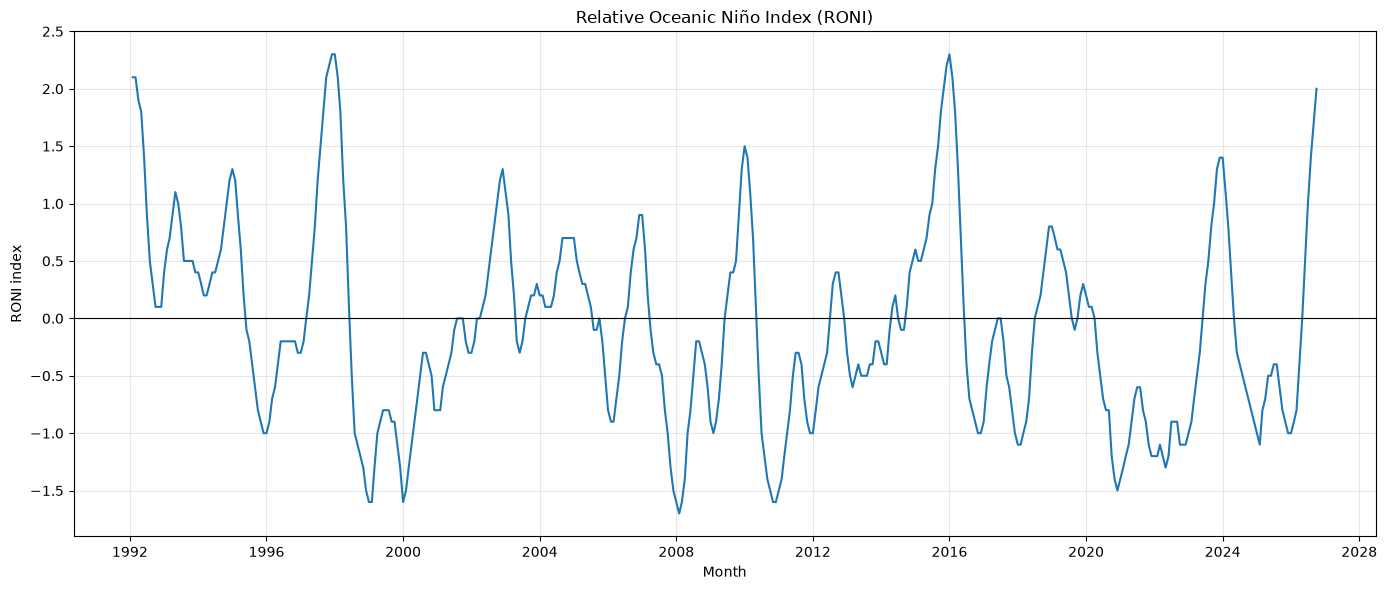

In [6]:
# Assign each three-month RONI value to its ending month
season_end_month = {
    "DJF": 2,
    "JFM": 3,
    "FMA": 4,
    "MAM": 5,
    "AMJ": 6,
    "MJJ": 7,
    "JJA": 8,
    "JAS": 9,
    "ASO": 10,
    "SON": 11,
    "OND": 12,
    "NDJ": 1,
}

years = pd.to_numeric(roni_table.iloc[:, 0], errors="coerce")
roni_table = roni_table.loc[years.between(1992, 2026)].copy()
roni_plot = roni_table.rename(columns={roni_table.columns[0]: "year"}).copy()
roni_plot["year"] = pd.to_numeric(roni_plot["year"], errors="coerce")
roni_long = roni_plot.melt(
    id_vars="year", var_name="season_label", value_name="roni_index"
)
roni_long["season"] = roni_long["season_label"].str.extract(
    r"^(DJF|JFM|FMA|MAM|AMJ|MJJ|JJA|JAS|ASO|SON|OND|NDJ)", expand=False
)
if roni_long["season"].isna().any():
    raise ValueError("RONI table contains an unrecognized season column")
roni_long["month"] = roni_long["season"].map(season_end_month)
roni_long["roni_index"] = pd.to_numeric(
    roni_long["roni_index"], errors="coerce"
)
roni_long["date"] = pd.to_datetime(
    {
        "year": roni_long["year"] + roni_long["month"].eq(1),
        "month": roni_long["month"],
        "day": 1,
    }
)
roni_monthly = roni_long[["date", "roni_index", "season"]].sort_values("date")

fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(roni_monthly["date"], roni_monthly["roni_index"])
ax.set_title("Relative Oceanic Niño Index (RONI)")
ax.set_xlabel("Month")
ax.set_ylabel("RONI index")
ax.axhline(0, color="black", linewidth=0.8)
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

## FRED dollar index and WTI inputs

In [7]:
FRED_API_URL = "https://api.stlouisfed.org/fred/series/observations"
FRED_API_KEY = "5951323032696d08a9a105cbb886698b"
if not FRED_API_KEY:
    raise RuntimeError(
        "Set the FRED_API_KEY environment variable before running this cell."
    )

FRED_SERIES = {
    "dxy_history": "DTWEXM",
    "dxy_current": "DTWEXBGS",
    "wti_price_usd": "DCOILWTICO",
}

def fetch_fred_series(series_id, column_name):
    response = requests.get(
        FRED_API_URL,
        params={
            "series_id": series_id,
            "api_key": FRED_API_KEY,
            "file_type": "json",
            "observation_start": "1992-01-01",
        },
        timeout=60,
    )
    response.raise_for_status()
    observations = response.json().get("observations")
    if not observations:
        raise ValueError(f"FRED returned no observations for {series_id}")
    result = pd.DataFrame(observations)[["date", "value"]].rename(
        columns={"value": column_name}
    )
    result["date"] = pd.to_datetime(result["date"])
    result[column_name] = pd.to_numeric(result[column_name], errors="coerce")
    return result.dropna(subset=[column_name])

dxy_history_daily = fetch_fred_series(
    FRED_SERIES["dxy_history"], "dxy_history"
)
dxy_current_daily = fetch_fred_series(
    FRED_SERIES["dxy_current"], "dxy_current"
)
wti_daily = fetch_fred_series(FRED_SERIES["wti_price_usd"], "wti_price_usd")

dxy_history_monthly = (
    dxy_history_daily.set_index("date").resample("MS").mean()
)
dxy_current_monthly = (
    dxy_current_daily.set_index("date").resample("MS").mean()
)
overlap = dxy_history_monthly.join(
    dxy_current_monthly, how="inner", lsuffix="_history", rsuffix="_current"
).dropna()
if overlap.empty:
    raise ValueError("FRED dollar-index series have no overlapping observations")
level_ratio = (overlap["dxy_current"] / overlap["dxy_history"]).median()
dxy_history_monthly["dxy_index"] = (
    dxy_history_monthly["dxy_history"] * level_ratio
)
dxy_current_monthly["dxy_index"] = dxy_current_monthly["dxy_current"]
dxy_monthly = pd.concat(
    [dxy_history_monthly[["dxy_index"]], dxy_current_monthly[["dxy_index"]]]
).sort_index()
dxy_monthly = dxy_monthly[~dxy_monthly.index.duplicated(keep="last")]
dxy_monthly = dxy_monthly.reset_index()

fred_monthly = (
    dxy_monthly.merge(wti_daily, on="date", how="outer")
    .set_index("date")
    .resample("MS")
    .mean()
    .reset_index()
)

market_inputs = wheat.merge(fred_monthly, on="date", how="left")
market_inputs.head(30)

,date,wheat_price_usd,target_return_1m,dxy_index,wti_price_usd
0,1992-01-01,169.954773,0.041355,105.568290,18.813158
1,1992-02-01,177.130600,-0.044915,107.745794,19.012500
2,1992-03-01,169.350739,-0.057228,110.505643,18.921818
3,1992-04-01,159.931198,-0.066183,110.065408,20.225263
4,1992-05-01,149.689117,-0.006860,108.711387,20.967368
5,1992-06-01,148.665726,-0.086702,106.319918,22.384545
6,1992-07-01,136.319016,-0.061652,103.837056,21.793182
7,1992-08-01,128.168488,0.079226,102.857995,21.339048
8,1992-09-01,138.735794,0.013214,103.722480,21.886190
9,1992-10-01,140.581284,0.048545,106.325459,21.685909


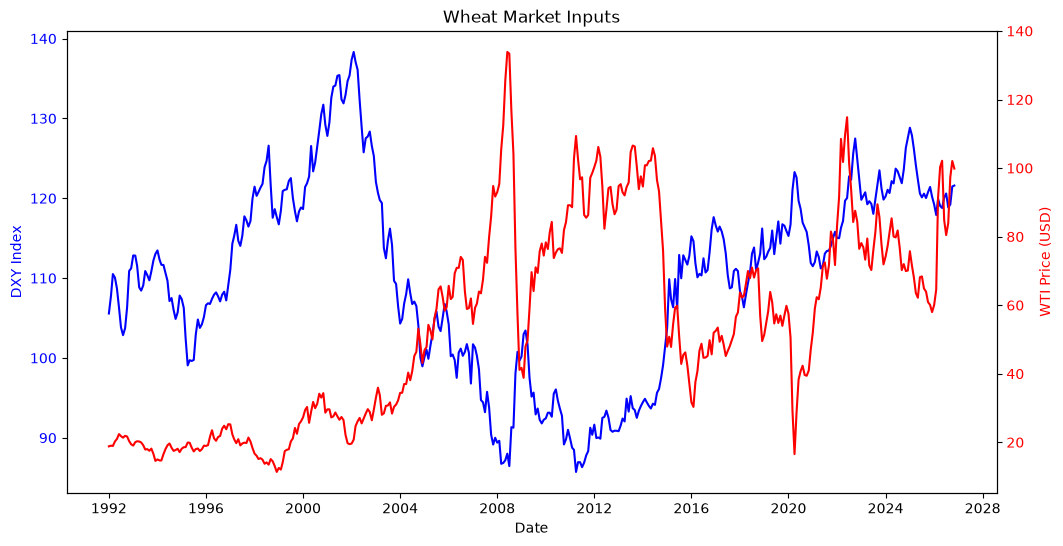

In [8]:
# Use matplotlib to plot dxy_index and wti_price_usd on the same figure with two y-axes
import matplotlib.pyplot as plt

fig, ax1 = plt.subplots(figsize=(12, 6))

ax1.plot(fred_monthly["date"], fred_monthly["dxy_index"], label="DXY Index", color="blue")
ax1.set_xlabel("Date")
ax1.set_ylabel("DXY Index", color="blue")
ax1.tick_params(axis="y", labelcolor="blue")

ax2 = ax1.twinx()
ax2.plot(fred_monthly["date"], fred_monthly["wti_price_usd"], label="WTI Price (USD)", color="red")
ax2.set_ylabel("WTI Price (USD)", color="red")
ax2.tick_params(axis="y", labelcolor="red")

plt.title("Wheat Market Inputs")
plt.show()

In [ ]:
import os
import re
import time
from pathlib import Path
from urllib.parse import urljoin
import requests
from bs4 import BeautifulSoup
from tqdm import tqdm
from io import BytesIO
from pypdf import PdfReader

BASE_URL = "https://esmis.nal.usda.gov"
LISTING_URL = f"{BASE_URL}/publication/world-agricultural-supply-and-demand-estimates"
OUTPUT_DIR = Path("./data/wasde_txt_reports")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Windows NT 10.0; Win64; x64) "
        "AppleWebKit/537.36 (KHTML, like Gecko) "
        "Chrome/120.0.0.0 Safari/537.36 (Research Project; contact@ensae.fr)"
    )
}

SESSION = requests.Session()
SESSION.headers.update(HEADERS)


def get_report_links_from_page(soup):
    reports = []

    for row in soup.select(".views-row, tr, article"):
        text = row.get_text(" ", strip=True)
        year_match = re.search(r"\b(199[2-9]|20[0-2][0-9])\b", text)

        if not year_match:
            continue

        year = int(year_match.group(0))
        pdf_anchor = row.find("a", href=re.compile(r"\.pdf(?:\?.*)?$", re.I))

        if pdf_anchor:
            reports.append({
                "year": year,
                "pdf_url": urljoin(BASE_URL, pdf_anchor["href"])
            })
            continue

        detail_anchor = row.find(
            "a", href=re.compile(r"/publication/|/reports/", re.I)
        )

        if detail_anchor:
            reports.append({
                "year": year,
                "detail_url": urljoin(BASE_URL, detail_anchor["href"])
            })

    return reports


def extract_pdf_url_from_detail_page(detail_url):
    response = SESSION.get(detail_url, timeout=20)
    response.raise_for_status()

    soup = BeautifulSoup(response.content, "html.parser")
    link = soup.find("a", href=re.compile(r"\.pdf(?:\?.*)?$", re.I))

    return urljoin(BASE_URL, link["href"]) if link else None


def download_and_extract_wheat(pdf_url, pdf_path):
    if pdf_path.exists():
        return

    response = SESSION.get(pdf_url, timeout=60)
    response.raise_for_status()
    pdf_path.write_bytes(response.content)

    reader = PdfReader(BytesIO(response.content))
    text = "\n".join(page.extract_text() or "" for page in reader.pages)

    paragraphs = [
        paragraph.strip()
        for paragraph in re.split(r"\n\s*\n", text)
        if re.search(r"\bwheat\b", paragraph, re.I)
    ]

    wheat_path = pdf_path.with_name(f"{pdf_path.stem}_wheat.txt")
    wheat_path.write_text("\n\n".join(paragraphs), encoding="utf-8")


def crawl_wasde_reports(start_page=0, max_pages=45):
    targets = []

    for page in range(start_page, max_pages):
        response = SESSION.get(
            f"{LISTING_URL}?page={page}",
            timeout=30
        )

        if response.status_code != 200:
            break

        items = get_report_links_from_page(
            BeautifulSoup(response.content, "html.parser")
        )

        if not items:
            break

        for item in items:
            pdf_url = item.get("pdf_url")

            if not pdf_url and item.get("detail_url"):
                pdf_url = extract_pdf_url_from_detail_page(item["detail_url"])

            if pdf_url:
                targets.append((item["year"], pdf_url))

        time.sleep(0.5)

    for year, pdf_url in tqdm(targets):
        filename = Path(pdf_url.split("?", 1)[0]).name
        if not filename.lower().endswith(".pdf"):
            filename = f"wasde_{year}.pdf"

        download_and_extract_wheat(pdf_url, OUTPUT_DIR / filename)
        time.sleep(0.2)


if __name__ == "__main__":
    crawl_wasde_reports()

In [ ]:
import re
from pathlib import Path
import numpy as np
import pandas as pd
from tqdm import tqdm

# ==============================================================================
# 1. LECTURE ROBUSTE ET EXTRACTION DE TEXTE
# ==============================================================================

def load_wasde_text(file_path: Path) -> str:
    """
    Lit le fichier brut en testant les encodages usuels des rapports historiques.
    """
    for enc in ["utf-8", "latin-1", "cp1252", "ascii"]:
        try:
            with open(file_path, "r", encoding=enc) as f:
                return f.read()
        except UnicodeDecodeError:
            continue
    return ""


def extract_wasde_date(text: str) -> pd.Timestamp:
    """
    Extrait la date exacte de publication du rapport WASDE depuis son en-tête.
    Gère les variantes : 'October 12, 2012', 'Oct. 11, 2005', 'MAY 10 1995', etc.
    """
    head = text[:2500]  # La date figure toujours sur les premières lignes
    
    # Motif regex pour les dates écrites en toutes lettres
    date_pattern = r"(?:January|February|March|April|May|June|July|August|September|October|November|December|Jan|Feb|Mar|Apr|Jun|Jul|Aug|Sep|Oct|Nov|Dec)\.?\s+\d{1,2},?\s+\d{4}"
    match = re.search(date_pattern, head, re.IGNORECASE)
    
    if match:
        try:
            return pd.to_datetime(match.group(0))
        except Exception:
            pass
            
    # Motif alternatif : dates numériques usuelles (MM/DD/YYYY)
    numeric_pattern = r"\b(0?[1-9]|1[0-2])/(0?[1-9]|[12]\d|3[01])/(19\d{2}|20\d{2})\b"
    num_match = re.search(numeric_pattern, head)
    if num_match:
        try:
            return pd.to_datetime(num_match.group(0))
        except Exception:
            pass
            
    return pd.NaT


def extract_wheat_narrative(text: str) -> str:
    """
    Isole le bloc narratif consacré au blé (WHEAT) en ignorant les tables numériques.
    """
    # Nettoyage minimal des retours à la ligne superflus
    normalized_text = re.sub(r"\r\n|\r", "\n", text)
    
    # 1. Délimitation du début de la section WHEAT
    start_match = re.search(r"\n\s*WHEAT:\s*", normalized_text, re.IGNORECASE)
    if not start_match:
        # Variante avec titres soulignés ou projetés
        start_match = re.search(r"\n\s*WHEAT\b[^\n]*\n", normalized_text, re.IGNORECASE)
        
    if not start_match:
        return ""
        
    start_pos = start_match.end()
    remaining = normalized_text[start_pos:]
    
    # 2. Délimitation de la fin : s'arrête au prochain groupe de matières premières
    # ou au début des grands tableaux de synthèse
    end_match = re.search(
        r"\n\s*(?:COARSE GRAINS|CORN|FEED GRAINS|OILSEEDS|SOYBEANS|RICE|COTTON|WASDE-\d+|TABLE \d+):",
        remaining,
        re.IGNORECASE
    )
    
    section = remaining[:end_match.start()] if end_match else remaining[:5000]
    
    # 3. Nettoyage : retrait des lignes de tableaux purs (contenant beaucoup de chiffres alignés)
    clean_lines = []
    for line in section.split("\n"):
        line_clean = line.strip()
        # Si la ligne contient plus de 4 chiffres distincts espacés, c'est généralement une ligne de tableau
        if len(re.findall(r"\b\d+(?:\.\d+)?\b", line_clean)) >= 4:
            continue
        if len(line_clean) > 0:
            clean_lines.append(line_clean)
            
    return " ".join(clean_lines)


# ==============================================================================
# 2. ANALYSE DU SENTIMENT (MÉTHODE LOUGHRAN-MCDONALD & FINBERT)
# ==============================================================================

# Dictionnaire de tonalité financière simplifié inspiré de Loughran & McDonald (2011)
BULLISH_WHEAT_WORDS = {
    "drought", "dry", "deficit", "freeze", "frost", "damage", "reduced",
    "decline", "declining", "lower", "cut", "tight", "tightened", "shrinking",
    "drop", "dropped", "stress", "shortage", "delayed", "deteriorated", "poor"
}

BEARISH_WHEAT_WORDS = {
    "record", "favorable", "bumper", "exceed", "exceeded", "abundant",
    "expanded", "expansion", "increase", "increased", "increasing", "higher",
    "rebound", "rebounded", "surge", "surplus", "large", "larger", "adequate",
    "improved", "improving", "favorable", "heavy"
}


def score_lexical_sentiment(narrative: str) -> dict:
    """
    Score de sentiment spécifique au marché physique des matières premières.
    Un choc d'offre négatif (sécheresse, récolte en baisse) est haussier (Bullish) pour les cours.
    """
    tokens = re.findall(r"\b[a-z]+\b", narrative.lower())
    total_words = len(tokens)
    
    if total_words == 0:
        return {"lm_bullish_score": 0.0, "lm_bearish_score": 0.0, "lm_net_sentiment": 0.0}
        
    bull_count = sum(1 for w in tokens if w in BULLISH_WHEAT_WORDS)
    bear_count = sum(1 for w in tokens if w in BEARISH_WHEAT_WORDS)
    
    # Net sentiment normalisé entre -1 et +1
    net_sentiment = (bull_count - bear_count) / max(1, (bull_count + bear_count))
    
    return {
        "lm_bullish_score": bull_count / total_words,
        "lm_bearish_score": bear_count / total_words,
        "lm_net_sentiment": net_sentiment
    }


def compute_finbert_sentiment(narratives: list, batch_size: int = 16) -> list:
    """
    Pipeline optionnel via FinBERT (Session 2 / LLM) si transformers et torch sont installés.
    """
    try:
        from transformers import pipeline
        pipe = pipeline("text-classification", model="ProsusAI/finbert", top_k=None, truncation=True)
    except (ImportError, Exception) as e:
        print(f"Transformers non disponible ou GPU indisponible ({e}). Repli sur l'approche lexicale.")
        return [np.nan] * len(narratives)
        
    finbert_scores = []
    print("Inférence FinBERT en cours sur les résumés WASDE...")
    
    for i in tqdm(range(0, len(narratives), batch_size)):
        batch = [text[:512] if text else "neutral" for text in narratives[i:i + batch_size]]
        results = pipe(batch)
        for res in results:
            # FinBERT renvoie des probabilités pour positive, negative, neutral
            scores = {d["label"]: d["score"] for d in res}
            # En finance agricole : positive news pour la récolte = pression baissière sur le prix
            score_net = scores.get("positive", 0.0) - scores.get("negative", 0.0)
            finbert_scores.append(score_net)
            
    return finbert_scores


# ==============================================================================
# 3. PIPELINE COMPLET D'EXTRACTION VERS DATAFRAME
# ==============================================================================

def process_all_wasde_reports(raw_dir: Path, use_finbert: bool = False) -> pd.DataFrame:
    """
    Traite l'ensemble des fichiers .txt du dossier et construit un DataFrame indexé point-in-time.
    """
    files = sorted(list(raw_dir.glob("*.txt")))
    if not files:
        raise FileNotFoundError(f"Aucun fichier .txt trouvé dans {raw_dir.resolve()}")
        
    records = []
    print(f"Traitement de {len(files)} rapports WASDE...")
    
    for f in tqdm(files):
        content = load_wasde_text(f)
        if not content:
            continue
            
        pub_date = extract_wasde_date(content)
        if pd.isna(pub_date):
            # En dernier recours, extraction de la date dans le nom de fichier (ex: wasde_2012_wasde-10-12.txt)
            match_filename = re.search(r"(\d{4})[_-](\d{2})[_-](\d{2})", f.name)
            if match_filename:
                pub_date = pd.to_datetime("-".join(match_filename.groups()))
                
        wheat_text = extract_wheat_narrative(content)
        lexical = score_lexical_sentiment(wheat_text)
        
        records.append({
            "filename": f.name,
            "publication_date": pub_date,
            "narrative_length": len(wheat_text.split()),
            "wheat_narrative": wheat_text,
            "lm_bullish_score": lexical["lm_bullish_score"],
            "lm_bearish_score": lexical["lm_bearish_score"],
            "lm_net_sentiment": lexical["lm_net_sentiment"]
        })
        
    df = pd.DataFrame(records)
    df = df.dropna(subset=["publication_date"]).sort_values("publication_date")
    
    # Supprimer les éventuels doublons (deux téléchargements du même rapport)
    df = df.drop_duplicates(subset=["publication_date"], keep="last")
    
    # Inférence Transformer optionnelle
    if use_finbert:
        df["finbert_net_sentiment"] = compute_finbert_sentiment(df["wheat_narrative"].tolist())
        
    # Définition de l'index temporel
    df = df.set_index("publication_date")
    
    return df


if __name__ == "__main__":
    DATA_PATH = Path("./data/wasde_txt_reports")
    
    # Exécution du traitement
    df_wasde_nlp = process_all_wasde_reports(DATA_PATH, use_finbert=False)
    
    # Affichage d'un aperçu
    print("\nAperçu du DataFrame NLP extrait :")
    print(df_wasde_nlp[["narrative_length", "lm_net_sentiment"]].head())
    
    # Sauvegarde du signal propre pour réutilisation immédiate dans le notebook
    output_cache = Path("./data/wasde_sentiment_features.parquet")
    df_wasde_nlp.to_parquet(output_cache)
    print(f"\nDonnées de sentiment sauvegardées dans : {output_cache}")

Traitement de 351 rapports WASDE...


100%|██████████| 351/351 [00:02<00:00, 117.53it/s]



Aperçu du DataFrame NLP extrait :
                  narrative_length  lm_net_sentiment
publication_date                                    
1998-02-11                      83         -1.000000
1998-03-12                     111         -1.000000
1998-06-12                     128         -0.250000
1998-07-10                     178         -0.250000
1998-08-12                     226         -0.333333

Données de sentiment sauvegardées dans : data\wasde_sentiment_features.parquet


In [ ]:
# Load and display data\wasde_sentiment_features.parquet


df = pd.read_parquet('data\wasde_sentiment_features.parquet')
df.head()

# Use matplotlib to plot lm_net_sentiment over time
import matplotlib.pyplot as plt

plt.plot(df['lm_net_sentiment'])

<>:4: SyntaxWarning: invalid escape sequence '\w'
<>:4: SyntaxWarning: invalid escape sequence '\w'
C:\Users\natha\AppData\Local\Temp\ipykernel_19704\1392859110.py:4: SyntaxWarning: invalid escape sequence '\w'
  df = pd.read_parquet('data\wasde_sentiment_features.parquet')


NameError: name 'pd' is not defined